In [1]:
# show python version
import sys
print(sys.version)

3.12.11 (main, Jul 23 2025, 00:30:17) [Clang 20.1.4 ]


In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from eval.metrics import rollout_metrics
from eval.trajectory import load_input_trajectory, simulate_input_trajectory
from io_utils import load_dataset_npz
from visualization import animate_cart_pendulum, plot_states_and_input


## 1. Fixed Initial State

The initial condition comes from the existing dataset metadata, which stores the agreed impulse-derived state.

In [3]:
DATASET_PATH = ROOT / "data/full_example/random_walk_dataset.npz"

dataset = load_dataset_npz(DATASET_PATH)
initial_state = dataset["initial_state"]
dataset_dt = float(np.mean(np.diff(dataset["t"])))

print("initial_state =", initial_state)
print("dataset_dt =", dataset_dt)


initial_state = [0.01447063 0.06920296 0.17453293 0.84325554]
dataset_dt = 0.01001001001001001


## 2. Load Input Trajectory

Set `INPUT_TRAJECTORY_PATH` to a user trajectory. Leave it as `None` for the default 100-point zero-force input. If a file does not include time values, `INPUT_DT` is used to build the time grid, so different input lengths naturally produce different horizons.

In [ ]:
INPUT_TRAJECTORY_PATH = None
# Examples:
# INPUT_TRAJECTORY_PATH = ROOT / "artifacts/user_input.npy"
# INPUT_TRAJECTORY_PATH = ROOT / "artifacts/user_input.csv"

DEFAULT_NUM_INPUT_POINTS = 100
INPUT_DT = dataset_dt
FORCE_LIMIT = 5.0         # updated from 1.0 N to match empirical feasibility limit
INTERPOLATION = "previous"  # "previous" for held samples, or "linear"

trajectory = load_input_trajectory(
    INPUT_TRAJECTORY_PATH,
    default_num_points=DEFAULT_NUM_INPUT_POINTS,
    dt=INPUT_DT,
    force_limit=FORCE_LIMIT,
)

print("source =", trajectory.source)
print("input points =", trajectory.u.size)
print("horizon sec =", trajectory.t_end)
print("force min/max =", float(np.min(trajectory.u)), float(np.max(trajectory.u)))


## 3. Apply Trajectory to the System

The simulation uses `run_simulation` and the nonlinear dynamics already defined in `src/dynamics.py`. The simulation horizon is the horizon of the loaded input trajectory.

In [ ]:
sim = simulate_input_trajectory(
    trajectory,
    initial_state=initial_state,
    interpolation=INTERPOLATION,
    num_samples=max(2, trajectory.u.size),
)

metrics = rollout_metrics(sim.t, sim.y, sim.u)
t_settle = metrics.get("settle_and_remain_time")
t_end    = float(sim.t[-1])

print("simulation success =", sim.success)
print("message =", sim.message)
print("final_state =", sim.y[:, -1])
print()
print("=== Settle-and-remain metrics ===")
print(f"  success (settle-and-remain):  {metrics['success']}")
print(f"  settle_and_remain_time:       {t_settle}")
print(f"  post_settle_duration:         {metrics.get('post_settle_duration')}")
print(f"  settled_fraction:             {metrics.get('settled_fraction'):.3f}")
print(f"  post_settle_max_theta (deg):  {np.degrees(metrics.get('post_settle_max_theta', float('nan'))):.2f}")
if t_settle is not None:
    print(f"  t_settle / t_end:             {t_settle / t_end:.2%}  (must be ≤ 50% for success)")
print()
metrics


## 4. Visualize Result

These are the same plotting and animation helpers used elsewhere in the project.

In [ ]:
# Settle-band plot: theta over time with ±2° tolerance band shaded.
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

theta_deg = np.degrees(sim.y[2, :])
t = sim.t
t_settle = metrics.get("settle_and_remain_time")

# Top: theta in degrees
ax = axes[0]
ax.plot(t, theta_deg, color="steelblue", linewidth=1.5, label="θ (deg)")
ax.axhline(2.0,  color="green", linestyle="--", linewidth=1, label="±2° tolerance")
ax.axhline(-2.0, color="green", linestyle="--", linewidth=1)
if t_settle is not None:
    ax.axvspan(t_settle, t[-1], alpha=0.12, color="green", label=f"Settled (t_s={t_settle:.2f}s)")
ax.set_ylabel("θ (degrees)")
ax.set_title("Settle-and-Remain Evaluation")
ax.legend(loc="upper right")
ax.grid(True, alpha=0.3)

# Bottom: control force
ax2 = axes[1]
ax2.plot(t, sim.u, color="darkorange", linewidth=1.4, label="Force (N)")
ax2.axhline(0, color="k", linewidth=0.5)
ax2.set_xlabel("time (s)")
ax2.set_ylabel("force (N)")
ax2.legend(loc="upper right")
ax2.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

# Summary line
if t_settle is not None:
    post_dur = float(t[-1]) - t_settle
    print(f"Settled at t_s = {t_settle:.2f} s.  Remaining settled duration = {post_dur:.2f} s  "
          f"({'PASS' if t_settle <= float(t[-1]) / 2 else 'FAIL'}: t_s ≤ t_end/2 = {float(t[-1])/2:.1f}s)")
else:
    print("Trajectory never settled and remained within tolerances.")


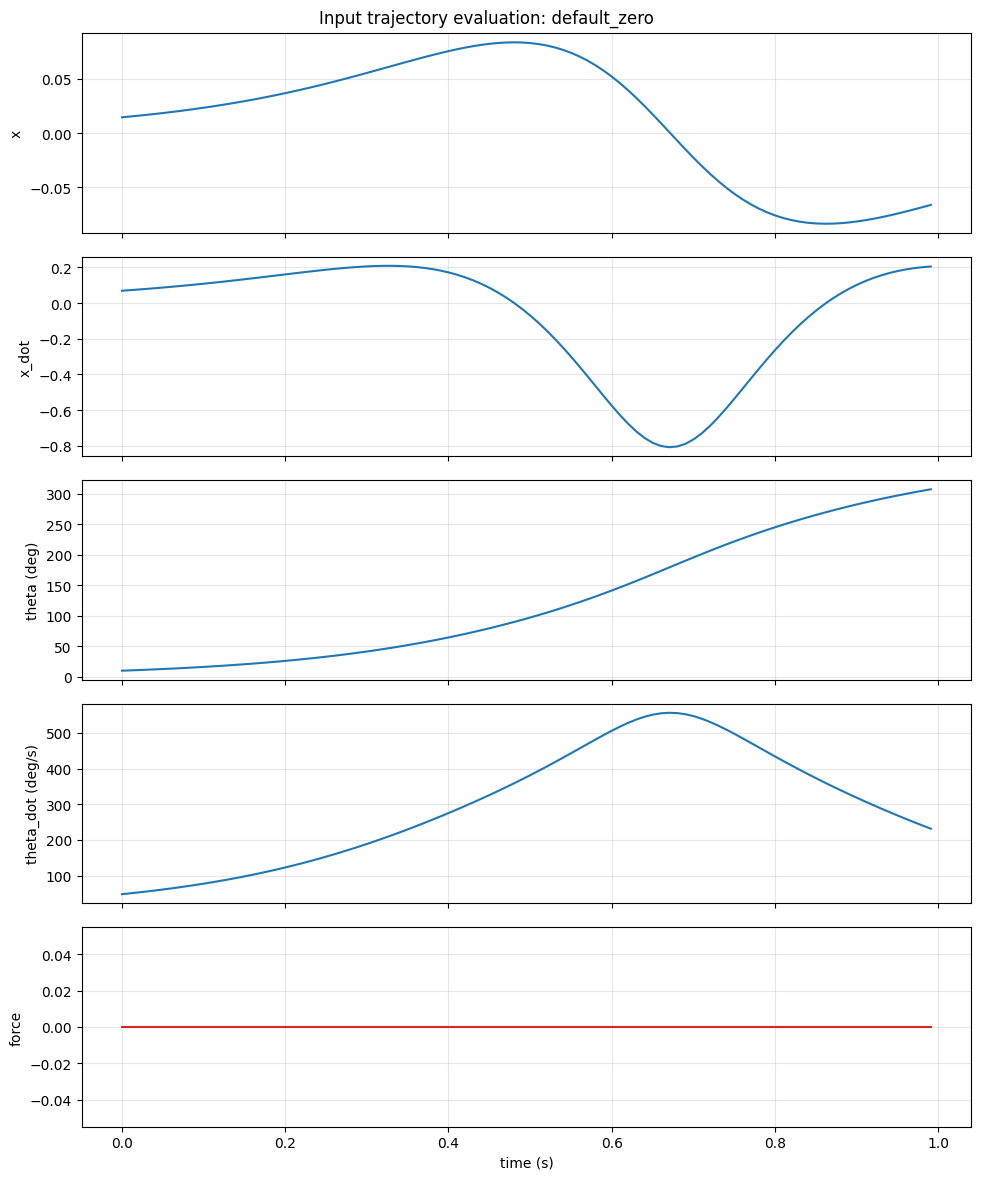

In [6]:
fig, axes = plot_states_and_input(
    sim.t,
    sim.y,
    sim.u,
    title=f"Input trajectory evaluation: {trajectory.source}",
    theta_in_degrees=True,
)
plt.show()


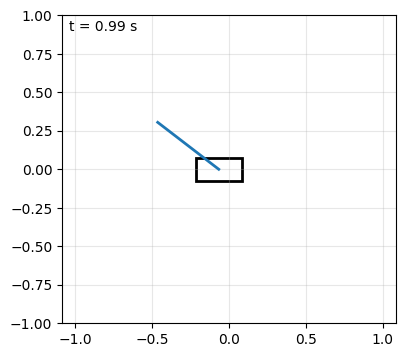

In [7]:
anim = animate_cart_pendulum(
    sim.t,
    sim.y,
    pendulum_length=0.5,
    stride=max(1, sim.t.size // 200),
)
display(HTML(anim.to_jshtml()))


## Optional: Save Evaluation Output

Run this cell when you want to persist the evaluated state/input/time arrays for comparison or grading.

In [8]:
SAVE_RESULT = False
OUTPUT_PATH = ROOT / "artifacts/evaluation/evaluate_trajectory_result.npz"

if SAVE_RESULT:
    OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        OUTPUT_PATH,
        t=sim.t,
        states=sim.y.T,
        inputs=sim.u,
        initial_state=initial_state,
        input_t=trajectory.t,
        input_u=trajectory.u,
    )
    print("saved", OUTPUT_PATH)
